[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/diogoflim/iap/blob/main/10_Transformers.ipynb)

# UNIVERSIDADE FEDERAL FLUMINENSE

**TCE11616 - Introdução ao Aprendizado Profundo**

**Prof.: Diogo Ferreira de Lima Silva**

---
# AULA 10 — TRANSFORMERS
---

Os **Transformers** são a arquitetura por trás do ChatGPT, do Claude, dos tradutores automáticos e de muitos modelos modernos de imagens. Eles foram criados para trabalhar com **sequências**: frases (sequências de palavras), séries temporais (sequências de medições), registros de sensores de uma máquina...

A peça central do Transformer é a **atenção**: cada elemento da sequência "olha" para todos os outros e decide em quais prestar mais atenção.

**O que você vai aprender**

- como funciona a **atenção**, passo a passo, com números pequenos;
- por que o Transformer precisa de **informação de posição**;
- usar as camadas prontas `nn.MultiheadAttention` e `nn.TransformerEncoder`;
- treinar um Transformer para reconhecer dígitos, tratando cada imagem como uma **sequência**;
- como isso se relaciona com os grandes modelos de linguagem.

> **Dica:** no Colab, use GPU. Em CPU, a aula leva cerca de 1 minuto.

## 0. Importando as bibliotecas

In [1]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(42)      # fixa a semente: os resultados ficam iguais a cada execução

# cores usadas nos gráficos
LARANJA, AZUL, VERDE, VERMELHO, CINZA = "#E08D2B", "#1F7A8C", "#2E7D4F", "#B3151A", "#5B6472"

---
## 1. A atenção, passo a passo
---

### Palavras como vetores

Uma rede não lê palavras: cada palavra (ou pedaço de palavra) é representada por um **vetor de números**, chamado **embedding**. Palavras com significado parecido têm vetores parecidos.

Para entender a atenção, vamos inventar embeddings de 3 números para a frase *"o gato bebeu leite"*. Pense nas três posições como "quanto a palavra tem a ver com animal", "com ação" e "com comida". (Em um modelo de verdade, os embeddings têm centenas de números e são **aprendidos**.)

In [2]:
palavras = ["o", "gato", "bebeu", "leite"]

X = torch.tensor([
    #  animal  ação  comida
    [  0.1,    0.1,  0.1 ],   # o
    [  1.0,    0.0,  0.2 ],   # gato
    [  0.0,    1.0,  0.5 ],   # bebeu
    [  0.2,    0.5,  1.0 ],   # leite
])
print("formato:", X.shape)     # 4 palavras, 3 números cada

formato: torch.Size([4, 3])


### Passo 1: o quanto cada palavra combina com cada outra

Uma forma simples de medir se dois vetores "combinam" é o **produto escalar**: multiplicar posição a posição e somar. Fazendo isso para todos os pares de uma vez, com uma multiplicação de matrizes:

In [3]:
pontuacoes = X @ X.T          # (4, 3) x (3, 4) = (4, 4): uma pontuação para cada par de palavras
print(pontuacoes.round(decimals=2))

tensor([[0.0300, 0.1200, 0.1500, 0.1700],
        [0.1200, 1.0400, 0.1000, 0.4000],
        [0.1500, 0.1000, 1.2500, 1.0000],
        [0.1700, 0.4000, 1.0000, 1.2900]])


### Passo 2: transformar pontuações em pesos

Aplicamos a **softmax** em cada linha (a mesma função que transforma as saídas de um classificador em probabilidades). Cada linha vira um conjunto de **pesos de atenção**, positivos e somando 1: quanto a palavra da linha "presta atenção" em cada palavra da coluna.

In [4]:
pesos = torch.softmax(pontuacoes, dim=1)
print(pesos.round(decimals=2))
print("soma de cada linha:", pesos.sum(dim=1))

tensor([[0.2300, 0.2500, 0.2600, 0.2600],
        [0.1700, 0.4300, 0.1700, 0.2300],
        [0.1400, 0.1300, 0.4100, 0.3200],
        [0.1300, 0.1700, 0.3000, 0.4000]])
soma de cada linha: tensor([1.0000, 1.0000, 1.0000, 1.0000])


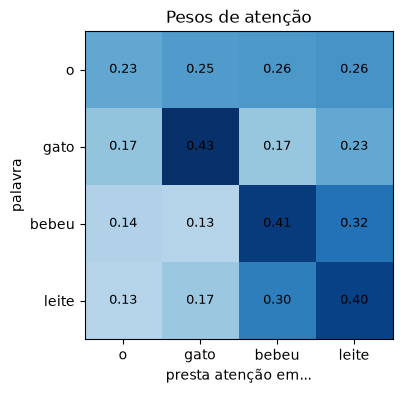

In [5]:
def desenha_atencao(pesos, palavras, titulo=""):
    plt.imshow(pesos, cmap="Blues", vmin=0, vmax=pesos.max())
    plt.xticks(range(len(palavras)), palavras); plt.yticks(range(len(palavras)), palavras)
    for i in range(len(palavras)):
        for j in range(len(palavras)):
            plt.text(j, i, f"{pesos[i, j]:.2f}", ha="center", va="center", fontsize=9)
    plt.xlabel("presta atenção em..."); plt.ylabel("palavra"); plt.title(titulo)

plt.figure(figsize=(4.5, 4))
desenha_atencao(pesos, palavras, "Pesos de atenção")
plt.show()

Repare que cada palavra presta mais atenção em si mesma, o que é natural, já que um vetor sempre combina consigo. Depois disso, **"leite"** presta mais atenção em **"bebeu"** (as duas têm a ver com ação e comida), enquanto "o", que não tem muito significado, distribui sua atenção quase igualmente.

### Passo 3: misturar

A saída da atenção para cada palavra é uma **média ponderada** dos vetores de todas as palavras, usando os pesos de atenção:

In [6]:
saida = pesos @ X             # (4, 4) x (4, 3) = (4, 3)
print("antes :", X[3])
print("depois:", saida[3].round(decimals=2), "  <- 'leite' agora carrega um pouco de 'bebeu'")

antes : tensor([0.2000, 0.5000, 1.0000])
depois: tensor([0.2600, 0.5200, 0.6000])   <- 'leite' agora carrega um pouco de 'bebeu'


Depois da atenção, cada palavra passa a carregar informação do **contexto**. É isso que permite, por exemplo, distinguir "banco" (de sentar) de "banco" (financeiro): o vetor de "banco" é misturado com os vetores das palavras ao redor.

Em resumo, a atenção são só três contas:

$$ \text{pesos} = \text{softmax}(X X^\top), \qquad \text{saída} = \text{pesos} \cdot X $$

---
## 2. A atenção não sabe a ordem das palavras
---

Vamos embaralhar a frase para *"leite bebeu o gato"* e calcular a atenção de novo:

In [7]:
def atencao(X):
    pesos = torch.softmax(X @ X.T, dim=1)
    return pesos @ X

nova_ordem = [3, 2, 0, 1]                    # leite, bebeu, o, gato
saida_original = atencao(X)
saida_embaralhada = atencao(X[nova_ordem])

for i, j in enumerate(nova_ordem):
    print(f"{palavras[j]:<6} original: {saida_original[j].numpy().round(3)} | embaralhada: {saida_embaralhada[i].numpy().round(3)}")

leite  original: [0.259 0.515 0.599] | embaralhada: [0.259 0.515 0.599]
bebeu  original: [0.208 0.586 0.566] | embaralhada: [0.208 0.586 0.566]
o      original: [0.326 0.412 0.465] | embaralhada: [0.326 0.412 0.465]
gato   original: [0.494 0.3   0.415] | embaralhada: [0.494 0.3   0.415]


Os resultados de cada palavra são **idênticos**: a atenção só olha **quais** palavras existem, não **onde** estão. Para ela, "o gato bebeu leite" e "leite bebeu o gato" são a mesma coisa!

Por isso, todo Transformer soma ao embedding de cada palavra um **vetor de posição** (*positional embedding*), que muda conforme a posição na sequência. Veremos na Seção 5 o que acontece quando esquecemos dele.

---
## 3. Atenção com parâmetros aprendidos
---

Na nossa versão simples, a atenção não tem nenhum parâmetro para aprender. No Transformer de verdade, cada palavra gera três vetores diferentes, através de três camadas `nn.Linear`:

- **consulta** (*query*, $Q$): "o que eu estou procurando?";
- **chave** (*key*, $K$): "o que eu ofereço?";
- **valor** (*value*, $V$): "o que eu passo adiante, se prestarem atenção em mim".

As contas são as mesmas de antes, só que com $Q$, $K$ e $V$ no lugar de $X$:

$$ \text{pesos} = \text{softmax}\left(\frac{Q K^\top}{\sqrt{d}}\right), \qquad \text{saída} = \text{pesos} \cdot V $$

(A divisão por $\sqrt{d}$, onde $d$ é o tamanho dos vetores, só evita números grandes demais na softmax.)

O PyTorch traz isso pronto em `nn.MultiheadAttention`. O "multi-head" significa que ele calcula várias atenções em paralelo (**cabeças**), cada uma podendo prestar atenção em aspectos diferentes.

In [8]:
atencao_pt = nn.MultiheadAttention(embed_dim=8, num_heads=2, batch_first=True)

sequencias = torch.randn(5, 4, 8)      # (lote, comprimento da sequência, tamanho do vetor)
saida_pt, pesos_pt = atencao_pt(sequencias, sequencias, sequencias)    # consulta, chave, valor

print("entrada:", sequencias.shape)
print("saída  :", saida_pt.shape)          # mesmo formato da entrada
print("pesos  :", pesos_pt.shape)          # para cada sequência, uma matriz 4 x 4 de atenção

entrada: torch.Size([5, 4, 8])
saída  : torch.Size([5, 4, 8])
pesos  : torch.Size([5, 4, 4])


> **Formato das sequências no PyTorch:** `(lote, comprimento, tamanho do vetor)`. Com `batch_first=True`, o lote vem primeiro, como em todas as aulas anteriores.

---
## 4. O bloco Transformer
---

Um **bloco Transformer** (chamado de *encoder layer*) junta peças que você já conhece:

```
x ──→ [ atenção ] ──→ ( + x ) ──→ [ normalização ] ──→ [ MLP ] ──→ ( + ) ──→ [ normalização ] ──→ saída
```

- **atenção**: cada elemento olha para os outros (Seções 1 a 3);
- **MLP**: uma pequena rede `Linear → ReLU → Linear` aplicada a cada elemento (Aulas 03 e 04);
- **atalhos residuais** ( + ) e **normalização**: exatamente as ideias da Aula 09, que permitem empilhar muitos blocos.

O PyTorch traz o bloco pronto, e o `nn.TransformerEncoder` empilha vários deles:

In [9]:
bloco = nn.TransformerEncoderLayer(d_model=64, nhead=4, dim_feedforward=128, batch_first=True)
encoder = nn.TransformerEncoder(bloco, num_layers=2)      # 2 blocos empilhados

x = torch.randn(5, 28, 64)
print("entrada:", x.shape)
print("saída  :", encoder(x).shape)      # o formato não muda
print("parâmetros:", sum(p.numel() for p in encoder.parameters()))

entrada: torch.Size([5, 28, 64])
saída  : torch.Size([5, 28, 64])
parâmetros: 66944


---
## 5. Aplicação: lendo dígitos linha por linha
---

Para treinar um Transformer de verdade sem precisar de textos e vocabulários, vamos usar um truque: tratar cada imagem do **MNIST** como uma **sequência de 28 linhas**. Cada linha da imagem ($28$ pixels) é um elemento da sequência, como se fosse uma "palavra".

```
imagem 28 x 28   →   sequência de 28 elementos, cada um com 28 números
```

O Transformer vai ler as 28 linhas e, através da atenção, combinar a informação de todas elas para decidir qual é o dígito.

como sequência: torch.Size([28, 28])


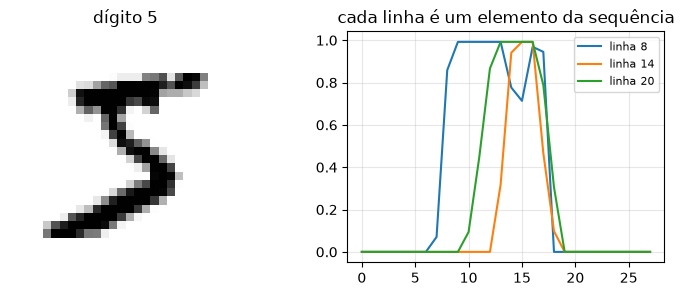

In [10]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

treino = datasets.MNIST(root="dados", train=True,  download=True, transform=transforms.ToTensor())
teste  = datasets.MNIST(root="dados", train=False, download=True, transform=transforms.ToTensor())

carregador_treino = DataLoader(treino, batch_size=64, shuffle=True)
carregador_teste  = DataLoader(teste, batch_size=1000)

imagem, rotulo = treino[0]
sequencia = imagem.squeeze(0)        # (1, 28, 28) -> (28, 28): 28 linhas, cada uma com 28 pixels
print("como sequência:", sequencia.shape)

plt.figure(figsize=(9, 3))
plt.subplot(1, 2, 1); plt.imshow(sequencia, cmap="gray_r"); plt.title(f"dígito {rotulo}"); plt.axis("off")
plt.subplot(1, 2, 2)
for i in [8, 14, 20]:
    plt.plot(sequencia[i], label=f"linha {i}")
plt.title("cada linha é um elemento da sequência"); plt.legend(fontsize=8); plt.grid(alpha=0.3)
plt.show()

### O modelo

O modelo tem quatro partes:

1. **embedding**: uma `nn.Linear(28, 64)` transforma cada linha (28 pixels) em um vetor de 64 números;
2. **posição**: somamos um vetor **aprendido** diferente para cada uma das 28 posições. Usamos `nn.Parameter`, que cria um tensor de parâmetros que o otimizador vai ajustar;
3. **encoder**: 2 blocos Transformer;
4. **classificação**: tiramos a média dos 28 vetores de saída e usamos uma `nn.Linear(64, 10)` para escolher o dígito.

O argumento `usar_posicao` permite ligar ou desligar o passo 2, para testarmos sua importância.

In [11]:
class TransformerMNIST(nn.Module):
    def __init__(self, usar_posicao=True):
        super().__init__()
        self.usar_posicao = usar_posicao
        self.embedding = nn.Linear(28, 64)
        self.posicao = nn.Parameter(torch.zeros(1, 28, 64))      # um vetor para cada uma das 28 posições
        bloco = nn.TransformerEncoderLayer(d_model=64, nhead=4, dim_feedforward=128, dropout=0.0, batch_first=True)
        self.encoder = nn.TransformerEncoder(bloco, num_layers=2)
        self.saida = nn.Linear(64, 10)

    def forward(self, imagens):
        x = imagens.squeeze(1)              # (lote, 1, 28, 28) -> (lote, 28, 28)
        x = self.embedding(x)               # (lote, 28, 64)
        if self.usar_posicao:
            x = x + self.posicao            # soma a informação de posição
        x = self.encoder(x)                 # (lote, 28, 64)
        x = x.mean(dim=1)                   # média das 28 posições -> (lote, 64)
        return self.saida(x)                # (lote, 10)


modelo = TransformerMNIST()
print("parâmetros:", sum(p.numel() for p in modelo.parameters()))
print("saída para um lote de 5 imagens:", modelo(torch.zeros(5, 1, 28, 28)).shape)

parâmetros: 71242
saída para um lote de 5 imagens: torch.Size([5, 10])


### Treinando

O laço de treino é **o mesmo** de todas as aulas. Isso mostra a vantagem de seguir sempre o mesmo padrão no PyTorch: mudamos a arquitetura de uma reta para um Transformer, e o resto continua igual.

> Cada treino leva cerca de 20 segundos em CPU.

In [12]:
dispositivo = "cuda" if torch.cuda.is_available() else "cpu"


def acuracia(modelo):
    modelo.eval()
    acertos = 0
    with torch.no_grad():
        for imagens, rotulos in carregador_teste:
            imagens, rotulos = imagens.to(dispositivo), rotulos.to(dispositivo)
            acertos += (modelo(imagens).argmax(dim=1) == rotulos).sum().item()
    return acertos / len(teste)


def treinar(modelo, epocas=3):
    modelo.to(dispositivo)
    perda_fn = nn.CrossEntropyLoss()
    otimizador = torch.optim.Adam(modelo.parameters(), lr=0.001)
    for epoca in range(epocas):
        modelo.train()
        for imagens, rotulos in carregador_treino:
            imagens, rotulos = imagens.to(dispositivo), rotulos.to(dispositivo)
            perda = perda_fn(modelo(imagens), rotulos)
            otimizador.zero_grad()
            perda.backward()
            otimizador.step()
        print(f"época {epoca + 1}: acurácia no teste = {acuracia(modelo):.2%}")


torch.manual_seed(42)
transformer = TransformerMNIST(usar_posicao=True)
treinar(transformer)

época 1: acurácia no teste = 96.41%


época 2: acurácia no teste = 96.76%


época 3: acurácia no teste = 97.66%


O Transformer lê os dígitos linha por linha e acerta cerca de **97%**, com um modelo de apenas 71 mil parâmetros.

### E sem a informação de posição?

Lembre da Seção 2: sem os vetores de posição, a atenção não sabe a **ordem** das linhas. Para ela, uma imagem e a mesma imagem com as linhas embaralhadas seriam iguais.

In [13]:
torch.manual_seed(42)
transformer_sem_posicao = TransformerMNIST(usar_posicao=False)
treinar(transformer_sem_posicao)

época 1: acurácia no teste = 85.72%


época 2: acurácia no teste = 88.62%


época 3: acurácia no teste = 89.21%


A acurácia cai bastante. Sem saber a ordem, o modelo só sabe **quais** linhas existem na imagem, mas não **onde** estão. Um "6" e um "9", por exemplo, têm linhas parecidas em ordens diferentes.

O mesmo vale para texto: sem posição, "o cachorro mordeu o homem" e "o homem mordeu o cachorro" seriam idênticos.

### Vendo as previsões

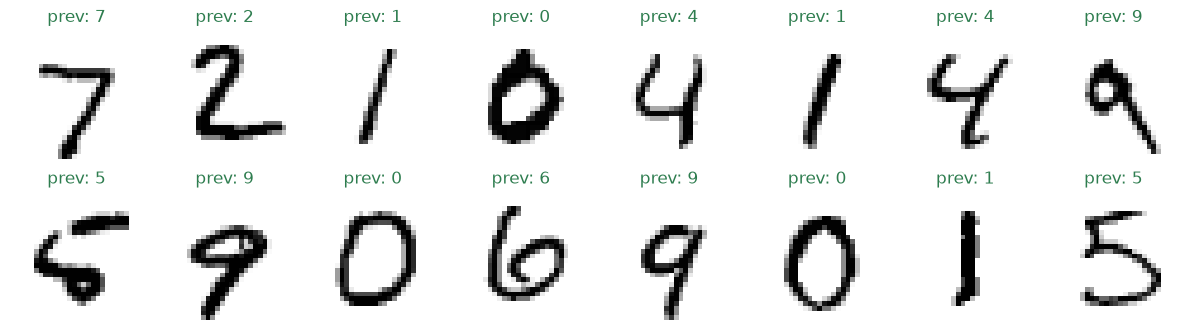

In [14]:
imagens, rotulos = next(iter(carregador_teste))
transformer.eval()
with torch.no_grad():
    previstos = transformer(imagens.to(dispositivo)).argmax(dim=1).cpu()

plt.figure(figsize=(12, 3.5))
for i in range(16):
    plt.subplot(2, 8, i + 1)
    plt.imshow(imagens[i][0], cmap="gray_r"); plt.axis("off")
    cor = VERDE if previstos[i] == rotulos[i] else VERMELHO
    plt.title(f"prev: {previstos[i].item()}", color=cor)
plt.tight_layout(); plt.show()

---
## 6. Transformers no mundo real
---

Os grandes modelos de linguagem (como ChatGPT e Claude) usam exatamente as peças desta aula, só que em uma escala enorme:

| | nosso Transformer | modelo de linguagem grande |
|---|---|---|
| elemento da sequência | uma linha da imagem | um **token** (pedaço de palavra) |
| tamanho da sequência | 28 | milhares a centenas de milhares de tokens |
| tamanho dos vetores | 64 | milhares |
| blocos empilhados | 2 | dezenas a mais de uma centena |
| parâmetros | ~70 mil | bilhões |
| tarefa de treino | classificar o dígito | **prever o próximo token** de bilhões de textos |

Para usar Transformers já treinados (para classificar textos, resumir, traduzir...), a biblioteca mais usada é a **Hugging Face Transformers**. Por exemplo, para analisar o sentimento de frases bastam poucas linhas:

```python
from transformers import pipeline

classificador = pipeline("sentiment-analysis")
classificador("A entrega chegou antes do prazo e o produto é ótimo!")
```

É o mesmo princípio do *transfer learning* da Aula 09: aproveitar um modelo enorme, já treinado, em um problema novo.

---
## Exercícios
---

**1.** Na Seção 1, mude o embedding de "o" para `[0.0, 0.0, 0.0]`. Como ficam os pesos de atenção dessa palavra? Por quê?

**2.** Na Seção 5, use 4 blocos (`num_layers=4`) em vez de 2. A acurácia melhora? E o tempo de treino?

**3.** Ainda na Seção 5, troque `x.mean(dim=1)` por `x[:, -1]` (usar só o vetor da **última** linha para classificar). O modelo ainda funciona? Por que a atenção permite isso?

**4.** Treine o `TransformerMNIST` no **Fashion-MNIST** e compare com a CNN da Aula 08. Qual acerta mais?